
# Proyecto Final APO 3
## 02. Preprocesamiento de imágenes

### Objetivo
Preparar las fotografías de frutas para su utilización en modelos
de Machine Learning y Deep Learning, mediante técnicas de
procesamiento digital de imágenes.

### Procedimientos
1. Carga y validación de imágenes.
2. Redimensionamiento conservando las proporciones.
3. Normalización de los valores RGB.
4. Segmentación de la fruta respecto al fondo.
5. Recorte de la región de interés.
6. Extracción de características mediante histogramas RGB.
7. Aumento de datos para entrenamiento.

### Propósito
Reducir diferencias innecesarias entre fotografías, conservar
la información visual relevante para determinar la calidad
y obtener representaciones compatibles con los modelos.

La segmentación será evaluada experimentalmente antes de
utilizarla de forma automática en el dataset completo.


In [2]:

from pathlib import Path
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Buscar la raíz del proyecto
directorio_actual = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        carpeta
        for carpeta in (
            directorio_actual,
            *directorio_actual.parents
        )
        if (
            carpeta / "src" / "data" / "preprocess.py"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró la carpeta principal del proyecto."
    )

# Permitir importar nuestras funciones
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.preprocess import (
    load_image_rgb,
    resize_with_padding,
    resize_and_normalize,
    segment_fruit_uniform_background,
    crop_to_foreground,
    extract_color_histogram,
    extract_combined_features,
    augment_training_image
)

print("Proyecto:", PROJECT_ROOT)
print("Python utilizado:", sys.executable)
print("Librerías importadas correctamente.")


Proyecto: /home/anderson/Descargas/Apo3/ProyectoFInalAPO3/ProyectoFinalAPO3
Python utilizado: /home/anderson/anaconda3/bin/python
Librerías importadas correctamente.



## 1. Carga de imágenes

Las imágenes del dataset pueden presentar distintas dimensiones
y características de captura.

Se utiliza OpenCV para leer las fotografías. Como OpenCV carga
las imágenes en BGR, se realiza una conversión a RGB para
trabajar con una representación consistente.

También se verifica que la imagen pueda leerse correctamente.

En esta primera prueba se utilizará una imagen sintética si
todavía no se dispone de una fotografía real.


Utilizando imagen sintética de prueba.
Dimensiones: (200, 320, 3)
Tipo de datos: uint8


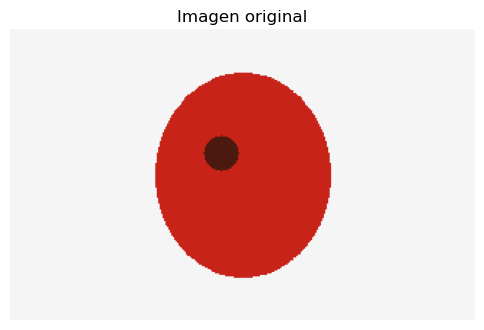

In [3]:

# Carpeta para imágenes de prueba
CARPETA_MUESTRAS = (
    PROJECT_ROOT
    / "data_raw"
    / "muestras_preprocesamiento"
)

extensiones = {".jpg", ".jpeg", ".png"}

rutas = []

if CARPETA_MUESTRAS.exists():
    rutas = sorted(
        ruta
        for ruta in CARPETA_MUESTRAS.rglob("*")
        if (
            ruta.is_file()
            and ruta.suffix.lower() in extensiones
        )
    )

ruta_real = rutas[0] if rutas else None

if ruta_real is not None:

    imagen_original = load_image_rgb(ruta_real)

    print("Fotografía real cargada:")
    print(ruta_real)

else:

    # Imagen de prueba creada con OpenCV
    imagen_original = np.full(
        (200, 320, 3),
        245,
        dtype=np.uint8
    )

    # Simulación de una fruta roja
    cv2.ellipse(
        imagen_original,
        (160, 100),
        (60, 70),
        0,
        0,
        360,
        (200, 35, 25),
        -1
    )

    # Simulación de una mancha
    cv2.circle(
        imagen_original,
        (145, 85),
        12,
        (75, 25, 15),
        -1
    )

    print("Utilizando imagen sintética de prueba.")

print("Dimensiones:", imagen_original.shape)
print("Tipo de datos:", imagen_original.dtype)

plt.figure(figsize=(6, 5))
plt.imshow(imagen_original)
plt.title("Imagen original")
plt.axis("off")
plt.show()



## 2. Redimensionamiento y normalización

Para entrenar los modelos es necesario trabajar con
imágenes de dimensiones consistentes.

Se utiliza un tamaño de 128 × 128 píxeles, conservando
la relación de aspecto mediante relleno.

Posteriormente se normalizan los valores RGB:

Valor_normalizado = Valor_original / 255

Así, los valores pasan del intervalo [0,255] al
intervalo [0,1].

El redimensionamiento no debe interpretarse como una
estimación del tamaño físico de la fruta.


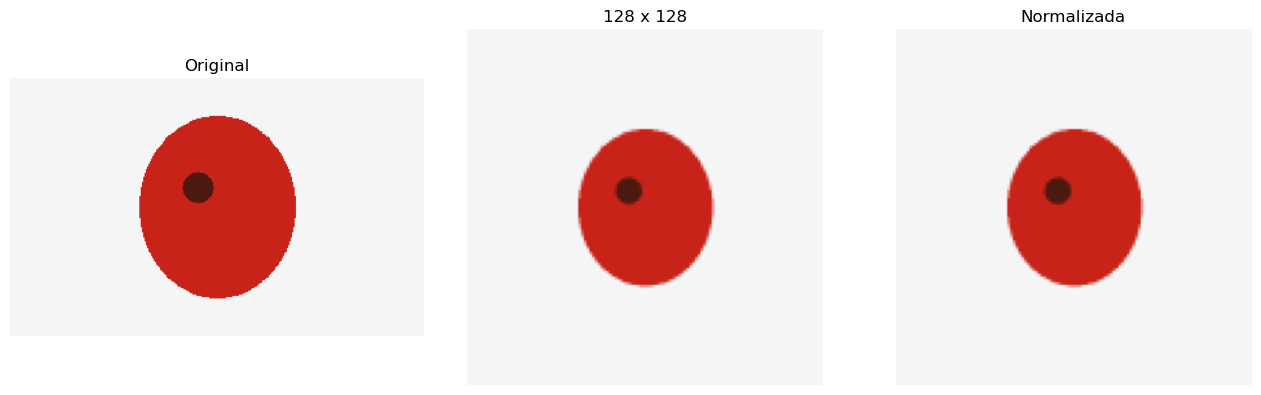

Dimensión original: (200, 320, 3)
Dimensión nueva: (128, 128, 3)
Tipo normalizado: float32
Rango de valores: 0.05882353 0.9607843


In [4]:

# Redimensionar sin deformar
imagen_redimensionada = resize_with_padding(
    imagen_original,
    target_size=(128, 128)
)

# Normalizar
imagen_normalizada = (
    imagen_redimensionada.astype(np.float32)
    / 255.0
)

# Comparación visual
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4)
)

axes[0].imshow(imagen_original)
axes[0].set_title("Original")

axes[1].imshow(imagen_redimensionada)
axes[1].set_title("128 x 128")

axes[2].imshow(imagen_normalizada)
axes[2].set_title("Normalizada")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensión original:", imagen_original.shape)
print("Dimensión nueva:", imagen_redimensionada.shape)
print("Tipo normalizado:", imagen_normalizada.dtype)

print(
    "Rango de valores:",
    imagen_normalizada.min(),
    imagen_normalizada.max()
)



## 3. Segmentación de la fruta

La segmentación permite identificar la región correspondiente
a la fruta y distinguirla del fondo de la fotografía.

El algoritmo desarrollado utiliza:

1. Conversión al espacio de color LAB.
2. Estimación del color del fondo.
3. Cálculo de distancias de color.
4. Umbralización para generar una máscara binaria.
5. Operaciones morfológicas para eliminar ruido.
6. Identificación de componentes conectados.
7. Recorte de la región de interés.

Los píxeles blancos de la máscara representan la región
detectada como fruta, mientras que los negros representan
el fondo.

El método es experimental y puede fallar cuando existen
sombras, fondos complejos o varias frutas en una imagen.


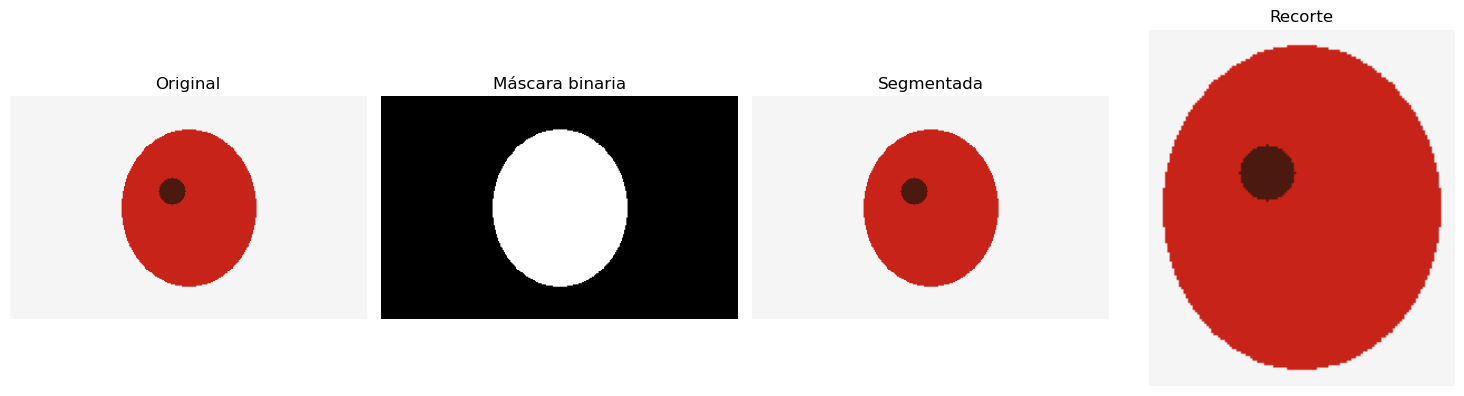

Porcentaje de imagen detectado: 20.90%


In [5]:

mascara = None

try:

    # Detectar la fruta
    mascara = segment_fruit_uniform_background(
        imagen_original
    )

    # Recortar la región detectada
    imagen_recortada, mascara_recortada = (
        crop_to_foreground(
            imagen_original,
            mascara
        )
    )

    # Crear imagen con fondo uniforme
    imagen_segmentada = imagen_original.copy()

    imagen_segmentada[mascara == 0] = (
        245, 245, 245
    )

    # Mostrar resultados
    fig, axes = plt.subplots(
        1, 4,
        figsize=(15, 4)
    )

    axes[0].imshow(imagen_original)
    axes[0].set_title("Original")

    axes[1].imshow(
        mascara,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1].set_title("Máscara binaria")

    axes[2].imshow(imagen_segmentada)
    axes[2].set_title("Segmentada")

    axes[3].imshow(imagen_recortada)
    axes[3].set_title("Recorte")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    porcentaje = (
        np.count_nonzero(mascara)
        / mascara.size
        * 100
    )

    print(
        f"Porcentaje de imagen detectado: "
        f"{porcentaje:.2f}%"
    )

except ValueError as error:

    mascara = None

    print("No se pudo segmentar automáticamente.")
    print("Motivo:", error)



## 4. Extracción de características de color

Los modelos tradicionales de Machine Learning necesitan
representaciones numéricas de los datos.

Para ello, utilizamos un histograma RGB tridimensional.

Cada uno de los tres canales se divide en 8 intervalos:

8 × 8 × 8 = 512 características.

El histograma representa la frecuencia relativa de
diferentes combinaciones de colores.

Se compara el histograma de toda la imagen con el
histograma calculado únicamente sobre la región de la fruta.

Las frecuencias se normalizan para que su suma sea 1.


Número de características: 512
Suma de frecuencias: 1.0
Suma del histograma segmentado: 1.0


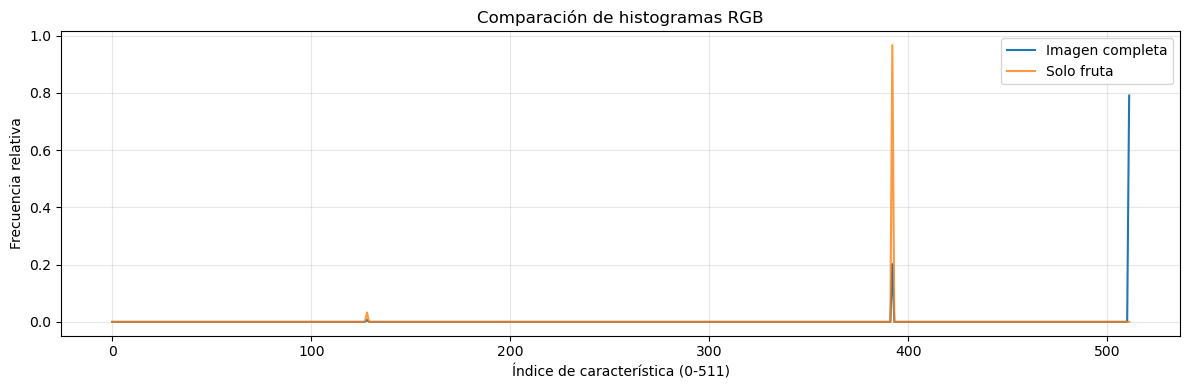

In [6]:

# Histograma de la imagen completa
histograma_completo = extract_color_histogram(
    imagen_original
)

print(
    "Número de características:",
    len(histograma_completo)
)

print(
    "Suma de frecuencias:",
    histograma_completo.sum()
)

plt.figure(figsize=(12, 4))

plt.plot(
    histograma_completo,
    label="Imagen completa",
    linewidth=1.5
)

# Comparar con histograma segmentado
if mascara is not None:

    histograma_fruta = extract_color_histogram(
        imagen_original,
        mask=mascara
    )

    plt.plot(
        histograma_fruta,
        label="Solo fruta",
        alpha=0.8
    )

    print(
        "Suma del histograma segmentado:",
        histograma_fruta.sum()
    )

plt.xlabel("Índice de característica (0-511)")
plt.ylabel("Frecuencia relativa")
plt.title("Comparación de histogramas RGB")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Data Augmentation

El aumento de datos consiste en generar modificaciones
moderadas de las fotografías disponibles.

En nuestro caso se utilizan:

- Rotaciones pequeñas.
- Variaciones controladas de iluminación.

Estas transformaciones permiten simular diferencias normales
entre fotografías.

El aumento de datos se utiliza exclusivamente durante el
entrenamiento, después de dividir los conjuntos de datos.

Debe verificarse que las transformaciones no oculten defectos
relevantes ni alteren la categoría de calidad.


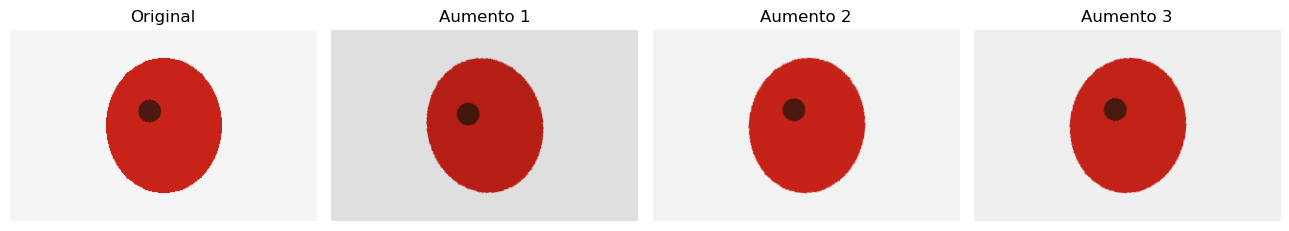

In [7]:

fig, axes = plt.subplots(
    1, 4,
    figsize=(13, 4)
)

axes[0].imshow(imagen_original)
axes[0].set_title("Original")
axes[0].axis("off")

semillas = [10, 20, 30]

for i, semilla in enumerate(
    semillas,
    start=1
):

    imagen_aumentada = augment_training_image(
        imagen_original,
        rng=np.random.default_rng(semilla)
    )

    axes[i].imshow(imagen_aumentada)

    axes[i].set_title(
        f"Aumento {i}"
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [8]:

if ruta_real is not None:

    vector = extract_combined_features(
        ruta_real
    )

else:

    vector = extract_color_histogram(
        imagen_normalizada
    )

print("Vector de características generado.")

print("Dimensiones:", vector.shape)
print("Tipo de datos:", vector.dtype)
print("Suma:", vector.sum())

# Verificaciones
assert vector.shape == (512,)
assert vector.dtype == np.float32
assert np.isclose(vector.sum(), 1.0)

print("Todas las verificaciones fueron correctas.")


Vector de características generado.
Dimensiones: (512,)
Tipo de datos: float32
Suma: 1.0
Todas las verificaciones fueron correctas.
